In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
#pip install matplotlib

# Metadata

In [2]:
metadata = pd.read_csv("../data/raw/BR-PVGen_metadata.csv")
metadata.head()

,brazil_federative_unit,id,is_panel_bifacial,nominal_power_mw,number_of_panels,panel_area_mm2,panel_bifaciality_coefficient,panel_efficiency_percentage,panel_temperature_coefficient,structure_type
0,SP,PS_001,True,5.0,12062,31516.36557,0.7,20.7,0.34,TRACKER
1,RJ,PS_002,True,1.0,2560,6688.93184,0.7,20.7,0.34,FIXED
2,RJ,PS_003,True,1.0,2560,6688.93184,0.7,20.7,0.34,FIXED
3,SP,PS_004,True,2.0,4480,13916.45696,0.7,21.1,0.34,FIXED
4,GO,PS_005,True,2.0,5032,13147.93165,0.7,20.7,0.34,TRACKER


In [3]:
metadata.shape

(51, 10)

In [4]:
metadata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 10 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   brazil_federative_unit         51 non-null     object 
 1   id                             51 non-null     object 
 2   is_panel_bifacial              51 non-null     bool   
 3   nominal_power_mw               51 non-null     float64
 4   number_of_panels               51 non-null     int64  
 5   panel_area_mm2                 51 non-null     float64
 6   panel_bifaciality_coefficient  51 non-null     float64
 7   panel_efficiency_percentage    51 non-null     float64
 8   panel_temperature_coefficient  51 non-null     float64
 9   structure_type                 51 non-null     object 
dtypes: bool(1), float64(5), int64(1), object(3)
memory usage: 3.8+ KB


In [5]:
metadata.isnull().sum()

brazil_federative_unit           0
id                               0
is_panel_bifacial                0
nominal_power_mw                 0
number_of_panels                 0
panel_area_mm2                   0
panel_bifaciality_coefficient    0
panel_efficiency_percentage      0
panel_temperature_coefficient    0
structure_type                   0
dtype: int64

In [6]:
metadata["id"].duplicated().sum()

np.int64(0)

In [7]:
metadata["brazil_federative_unit"].value_counts()

brazil_federative_unit
SP    30
GO     8
RJ     4
MG     4
MS     3
PR     1
BA     1
Name: count, dtype: int64

In [8]:
metadata["nominal_power_mw"].describe()

count    51.000000
mean      2.513725
std       0.959118
min       1.000000
25%       2.000000
50%       2.500000
75%       3.000000
max       5.000000
Name: nominal_power_mw, dtype: float64

In [9]:
metadata["structure_type"].value_counts()

structure_type
TRACKER    30
FIXED      21
Name: count, dtype: int64

# Inverter Data

In [10]:
inverter = pd.read_csv("../data/raw/BR-PVGen_inverter/PS_001.csv")
inverter.head()

,datetime,document_count_internal_temperature_celsius,document_count_total_active_power_w,document_count_total_dc_power_w,document_count_total_reactive_power_var,internal_temperature_celsius,interpolated_keys_internal_temperature_celsius,interpolated_keys_total_active_power_w,interpolated_keys_total_dc_power_w,interpolated_keys_total_reactive_power_var,inverter_id,ps_id,total_active_power_w,total_dc_power_w,total_reactive_power_var
0,2024-03-26T00:00:00Z,0,0,0,0,NaN,NaN,NaN,NaN,NaN,1,PS_001,NaN,NaN,NaN
1,2024-03-26T00:00:00Z,0,0,0,0,NaN,NaN,NaN,NaN,NaN,2,PS_001,NaN,NaN,NaN
2,2024-03-26T00:00:00Z,0,0,0,0,NaN,NaN,NaN,NaN,NaN,3,PS_001,NaN,NaN,NaN
3,2024-03-26T00:00:00Z,0,0,0,0,NaN,NaN,NaN,NaN,NaN,4,PS_001,NaN,NaN,NaN
4,2024-03-26T00:00:00Z,0,0,0,0,NaN,NaN,NaN,NaN,NaN,5,PS_001,NaN,NaN,NaN


In [11]:
inverter.shape

(1048575, 15)

In [12]:
inverter.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 15 columns):
 #   Column                                          Non-Null Count    Dtype  
---  ------                                          --------------    -----  
 0   datetime                                        1048575 non-null  object 
 1   document_count_internal_temperature_celsius     1048575 non-null  int64  
 2   document_count_total_active_power_w             1048575 non-null  int64  
 3   document_count_total_dc_power_w                 1048575 non-null  int64  
 4   document_count_total_reactive_power_var         1048575 non-null  int64  
 5   internal_temperature_celsius                    909275 non-null   float64
 6   interpolated_keys_internal_temperature_celsius  24435 non-null    object 
 7   interpolated_keys_total_active_power_w          24435 non-null    object 
 8   interpolated_keys_total_dc_power_w              24435 non-null    object 
 9   interpolated_

In [13]:
inverter[["datetime", "ps_id", "inverter_id", "total_active_power_w"]].head(10)

,datetime,ps_id,inverter_id,total_active_power_w
0,2024-03-26T00:00:00Z,PS_001,1,NaN
1,2024-03-26T00:00:00Z,PS_001,2,NaN
2,2024-03-26T00:00:00Z,PS_001,3,NaN
3,2024-03-26T00:00:00Z,PS_001,4,NaN
4,2024-03-26T00:00:00Z,PS_001,5,NaN
5,2024-03-26T00:00:00Z,PS_001,6,NaN
6,2024-03-26T00:00:00Z,PS_001,7,NaN
7,2024-03-26T00:00:00Z,PS_001,8,NaN
8,2024-03-26T00:00:00Z,PS_001,9,NaN
9,2024-03-26T00:00:00Z,PS_001,10,NaN


In [14]:
inverter[["total_active_power_w", "total_dc_power_w"]].isnull().sum()

total_active_power_w    139300
total_dc_power_w        139300
dtype: int64

In [15]:
inverter[[
    "datetime",
    "document_count_total_active_power_w",
    "total_active_power_w"
]].head(20)

,datetime,document_count_total_active_power_w,total_active_power_w
0,2024-03-26T00:00:00Z,0,NaN
1,2024-03-26T00:00:00Z,0,NaN
2,2024-03-26T00:00:00Z,0,NaN
3,2024-03-26T00:00:00Z,0,NaN
4,2024-03-26T00:00:00Z,0,NaN
5,2024-03-26T00:00:00Z,0,NaN
6,2024-03-26T00:00:00Z,0,NaN
7,2024-03-26T00:00:00Z,0,NaN
8,2024-03-26T00:00:00Z,0,NaN
9,2024-03-26T00:00:00Z,0,NaN


In [16]:
inverter.loc[
    inverter["total_active_power_w"].isnull(),
    ["datetime", "inverter_id", "document_count_total_active_power_w", "total_active_power_w"]
].head(10)
#selects rows where active power is missing.

,datetime,inverter_id,document_count_total_active_power_w,total_active_power_w
0,2024-03-26T00:00:00Z,1,0,NaN
1,2024-03-26T00:00:00Z,2,0,NaN
2,2024-03-26T00:00:00Z,3,0,NaN
3,2024-03-26T00:00:00Z,4,0,NaN
4,2024-03-26T00:00:00Z,5,0,NaN
5,2024-03-26T00:00:00Z,6,0,NaN
6,2024-03-26T00:00:00Z,7,0,NaN
7,2024-03-26T00:00:00Z,8,0,NaN
8,2024-03-26T00:00:00Z,9,0,NaN
9,2024-03-26T00:00:00Z,10,0,NaN


In [17]:
#Check missing values by hour
#We want to investigate whether missing power measurements are more common at particular hours.

inverter["datetime"] = pd.to_datetime(inverter["datetime"] , utc = True)

inverter["hour"] = inverter["datetime"].dt.hour

inverter.groupby("hour")["total_active_power_w"].apply(
    lambda x: x.isnull().mean()*100
)


hour
0     12.255708
1     12.908676
2     14.262557
3     15.296804
4     16.335616
5     16.136986
6     15.543379
7     16.545101
8     19.450046
9     14.170486
10    15.456004
11    14.110907
12    12.474794
13    12.218148
14    11.381760
15    10.098533
16    10.155820
17    10.025206
18    11.148029
19    11.704858
20    11.631531
21    11.952337
22    11.739230
23    11.787351
Name: total_active_power_w, dtype: float64

We learned that missing measurements cannot be explained by nighttime alone.

In [18]:
inverter.groupby(
    inverter["total_active_power_w"].isnull()
)["document_count_total_active_power_w"].describe()

,count,mean,std,min,25%,50%,75%,max
total_active_power_w,,,,,,,,
False,909275.0,2.250221,0.789462,0.0,2.0,2.0,3.0,16.0
True,139300.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0


In [19]:
inverter["total_active_power_w"].eq(0).sum()

np.int64(454752)

This means 454,752 available readings have a value exactly equal to zero. These are different from NaN, which means missing

In [20]:
inverter["total_active_power_w"].describe()


count    909275.000000
mean      32971.717371
std       45127.722138
min           0.000000
25%           0.000000
50%           0.000000
75%       73550.176135
max      126335.023700
Name: total_active_power_w, dtype: float64

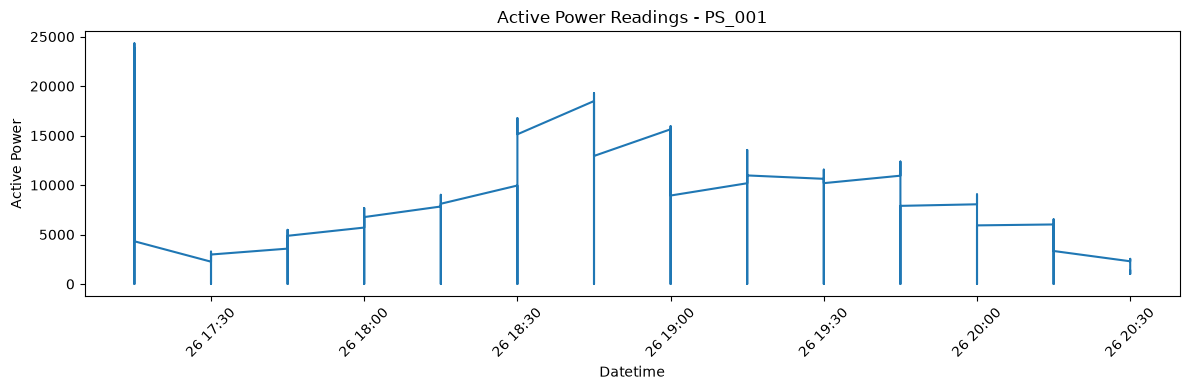

In [21]:
sample = inverter.dropna(subset=["total_active_power_w"]).head(500)
plt.figure(figsize=(12,4))

plt.plot(sample["datetime"] , sample["total_active_power_w"])
plt.xlabel("Datetime")
plt.ylabel("Active Power")
plt.title("Active Power Readings - PS_001")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

This plotted the first 500 rows with available active-power values. We observed changing power readings, but the graph connected measurements from multiple inverters at the same timestamps.

# weather (meteorological) data

In [22]:
weather = pd.read_csv("../data/raw/BR-PVGen_meteorological/PS_001.csv")
weather.head()

,ambient_temperature_celsius,battery_voltage,datetime,document_count_ambient_temperature_celsius,document_count_battery_voltage,document_count_ghi_irradiance_wm2,document_count_gri_irradiance_wm2,document_count_panel_temperature_celsius,document_count_poa_irradiance_wm2,document_count_precipitation_accumulated_mm,...,interpolated_keys_tracker_albedo_index,interpolated_keys_wind_direction_degrees,interpolated_keys_wind_speed_ms,panel_temperature_celsius,poa_irradiance_wm2,precipitation_accumulated_mm,ps_id,tracker_albedo_index,wind_direction_degrees,wind_speed_ms
0,NaN,NaN,2024-03-26T00:00:00Z,0,0,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,PS_001,NaN,NaN,NaN
1,NaN,NaN,2024-03-26T00:15:00Z,0,0,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,PS_001,NaN,NaN,NaN
2,NaN,NaN,2024-03-26T00:30:00Z,0,0,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,PS_001,NaN,NaN,NaN
3,NaN,NaN,2024-03-26T00:45:00Z,0,0,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,PS_001,NaN,NaN,NaN
4,NaN,NaN,2024-03-26T01:00:00Z,0,0,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,PS_001,NaN,NaN,NaN


In [23]:
weather.shape

(42336, 31)

In [24]:
weather.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42336 entries, 0 to 42335
Data columns (total 31 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   ambient_temperature_celsius                    41004 non-null  float64
 1   battery_voltage                                41001 non-null  float64
 2   datetime                                       42336 non-null  object 
 3   document_count_ambient_temperature_celsius     42336 non-null  int64  
 4   document_count_battery_voltage                 42336 non-null  int64  
 5   document_count_ghi_irradiance_wm2              42336 non-null  int64  
 6   document_count_gri_irradiance_wm2              42336 non-null  int64  
 7   document_count_panel_temperature_celsius       42336 non-null  int64  
 8   document_count_poa_irradiance_wm2              42336 non-null  int64  
 9   document_count_precipitation_accumulated_mm    423

In [25]:
weather.isnull().sum()

ambient_temperature_celsius                       1332
battery_voltage                                   1335
datetime                                             0
document_count_ambient_temperature_celsius           0
document_count_battery_voltage                       0
document_count_ghi_irradiance_wm2                    0
document_count_gri_irradiance_wm2                    0
document_count_panel_temperature_celsius             0
document_count_poa_irradiance_wm2                    0
document_count_precipitation_accumulated_mm          0
document_count_tracker_albedo_index                  0
document_count_wind_direction_degrees                0
document_count_wind_speed_ms                         0
ghi_irradiance_wm2                                1317
gri_irradiance_wm2                                1324
interpolated_keys_ambient_temperature_celsius    42279
interpolated_keys_battery_voltage                42280
interpolated_keys_ghi_irradiance_wm2             42278
interpolat

In [26]:
weather[[
    "datetime",
    "ghi_irradiance_wm2",
    "poa_irradiance_wm2",
    "ambient_temperature_celsius",
    "panel_temperature_celsius"
]].head(10)

,datetime,ghi_irradiance_wm2,poa_irradiance_wm2,ambient_temperature_celsius,panel_temperature_celsius
0,2024-03-26T00:00:00Z,NaN,NaN,NaN,NaN
1,2024-03-26T00:15:00Z,NaN,NaN,NaN,NaN
2,2024-03-26T00:30:00Z,NaN,NaN,NaN,NaN
3,2024-03-26T00:45:00Z,NaN,NaN,NaN,NaN
4,2024-03-26T01:00:00Z,NaN,NaN,NaN,NaN
5,2024-03-26T01:15:00Z,NaN,NaN,NaN,NaN
6,2024-03-26T01:30:00Z,NaN,NaN,NaN,NaN
7,2024-03-26T01:45:00Z,NaN,NaN,NaN,NaN
8,2024-03-26T02:00:00Z,NaN,NaN,NaN,NaN
9,2024-03-26T02:15:00Z,NaN,NaN,NaN,NaN


In [27]:
weather["datetime"] = pd.to_datetime(weather["datetime"], utc=True)

weather["hour"] = weather["datetime"].dt.hour

weather.groupby("hour")["ghi_irradiance_wm2"].apply(
    lambda x: x.isnull().mean() * 100
)

hour
0     2.721088
1     3.061224
2     3.287982
3     3.571429
4     4.081633
5     3.798186
6     3.741497
7     3.854875
8     3.571429
9     3.741497
10    3.514739
11    3.117914
12    3.117914
13    2.834467
14    2.777778
15    2.607710
16    2.777778
17    2.721088
18    3.004535
19    2.777778
20    2.210884
21    2.664399
22    2.551020
23    2.551020
Name: ghi_irradiance_wm2, dtype: float64

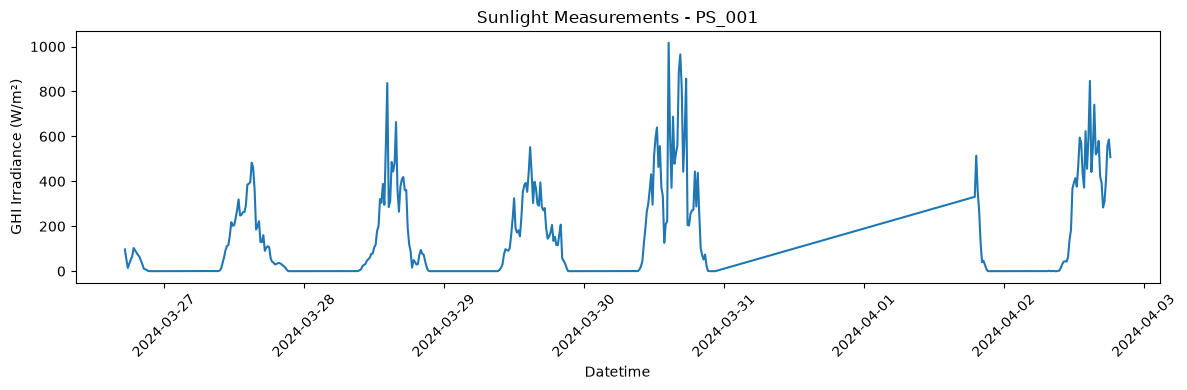

In [28]:
sample = weather.dropna(subset=["ghi_irradiance_wm2"]).head(500)

plt.figure(figsize=(12, 4))
plt.plot(sample["datetime"], sample["ghi_irradiance_wm2"])
plt.xlabel("Datetime")
plt.ylabel("GHI Irradiance (W/m²)")
plt.title("Sunlight Measurements - PS_001")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Sunlight varies over time and may help explain changes in solar power generation. However, the graph alone cannot tell us why every fluctuation occurred.

In [29]:
weather["datetime"].duplicated().sum()

np.int64(0)

In [30]:
inverter["datetime"].duplicated().sum()

np.int64(1022144)

In [31]:
inverter["datetime"].nunique()

26431

In [32]:
inverter["inverter_id"].nunique()

41

In [33]:
inverter["inverter_id"].value_counts()

inverter_id
1     26431
2     26431
3     26431
5     26431
6     26431
8     26431
7     26431
9     26431
10    26431
15    26431
12    26431
13    26431
14    26431
16    26431
28    26430
17    26430
18    26430
19    26430
20    26430
21    26430
23    26430
24    26430
25    26430
26    26430
27    26430
36    26430
29    26430
30    26430
31    26430
32    26430
33    26430
34    26430
35    26430
40    26430
37    26430
38    26430
39    26430
11    25854
4     23071
22    21630
91       96
Name: count, dtype: int64

In [34]:
inverter["datetime"].min(), inverter["datetime"].max()

(Timestamp('2024-03-26 00:00:00+0000', tz='UTC'),
 Timestamp('2024-12-26 07:30:00+0000', tz='UTC'))

In [35]:
inverter["ps_id"].unique()

array(['PS_001'], dtype=object)

In [36]:
weather["datetime"].min(), weather["datetime"].max()

(Timestamp('2024-03-26 00:00:00+0000', tz='UTC'),
 Timestamp('2025-06-09 23:45:00+0000', tz='UTC'))

In [37]:
weather["ps_id"].unique()

array(['PS_001'], dtype=object)

In [38]:
weather[[
    "ghi_irradiance_wm2",
    "poa_irradiance_wm2",
    "ambient_temperature_celsius",
    "panel_temperature_celsius",
    "wind_speed_ms"
]].describe()

,ghi_irradiance_wm2,poa_irradiance_wm2,ambient_temperature_celsius,panel_temperature_celsius,wind_speed_ms
count,41019.000000,41014.000000,41004.000000,41000.000000,40995.000000
mean,216.413916,257.727017,23.318649,25.276959,2.049273
std,312.077867,359.533740,5.100370,10.339638,1.251887
min,-7.071405,-8.078176,6.500000,3.183333,-0.279500
25%,-1.939299,-1.425391,19.889462,18.000000,1.130951
50%,1.825104,2.076329,22.697680,21.249123,1.954988
75%,400.073559,553.078436,27.100000,32.099998,2.785707
max,1387.276887,1453.773189,38.233577,61.098550,9.270000


In [39]:
weather["ghi_irradiance_wm2"].describe()

count    41019.000000
mean       216.413916
std        312.077867
min         -7.071405
25%         -1.939299
50%          1.825104
75%        400.073559
max       1387.276887
Name: ghi_irradiance_wm2, dtype: float64

In [40]:
# inspected negative GHI values
weather[weather["ghi_irradiance_wm2"] < 0][
    ["datetime", "ghi_irradiance_wm2", "poa_irradiance_wm2"]
].head(10)

,datetime,ghi_irradiance_wm2,poa_irradiance_wm2
4404,2024-05-10 21:00:00+00:00,-1.690252,-1.849808
4405,2024-05-10 21:15:00+00:00,-2.480172,-1.164986
4406,2024-05-10 21:30:00+00:00,-1.981856,-1.084604
4407,2024-05-10 21:45:00+00:00,-2.045899,-1.285422
4408,2024-05-10 22:00:00+00:00,-1.920822,-0.728355
4409,2024-05-10 22:15:00+00:00,-2.501994,-1.614384
4410,2024-05-10 22:30:00+00:00,-2.093790,-0.187277
4411,2024-05-10 22:45:00+00:00,-2.050189,-0.974867
4412,2024-05-10 23:00:00+00:00,-2.474475,-0.725212
4413,2024-05-10 23:15:00+00:00,-2.340020,-0.570222


we found small negative values, particularly during late-night hours

In [41]:
(weather["ghi_irradiance_wm2"] < 0).sum()

np.int64(17595)

In [42]:
(weather["poa_irradiance_wm2"] < 0).sum()

np.int64(19216)

In [43]:
weather[["ghi_irradiance_wm2", "poa_irradiance_wm2"]].min()

ghi_irradiance_wm2   -7.071405
poa_irradiance_wm2   -8.078176
dtype: float64

In [44]:
weather[weather["ghi_irradiance_wm2"] < 0][
    "ghi_irradiance_wm2"
].describe()

count    17595.000000
mean        -1.973468
std          0.820176
min         -7.071405
25%         -2.545984
50%         -2.103095
75%         -1.444123
max         -0.000105
Name: ghi_irradiance_wm2, dtype: float64

In [45]:
#We then replaced negative values in both columns with zero

weather.loc[weather["ghi_irradiance_wm2"] < 0, "ghi_irradiance_wm2"] = 0

weather.loc[weather["poa_irradiance_wm2"] < 0, "poa_irradiance_wm2"] = 0

In [46]:
weather[["ghi_irradiance_wm2", "poa_irradiance_wm2"]].min()

ghi_irradiance_wm2    0.0
poa_irradiance_wm2    0.0
dtype: float64

We applied a physical constraint that irradiance should not be negative. This is a cleaning decision we made for the project; we haven't established the exact cause of every negative reading.

In [47]:
weather[[
    "ghi_irradiance_wm2",
    "poa_irradiance_wm2",
    "ambient_temperature_celsius",
    "panel_temperature_celsius",
    "wind_speed_ms"
]].isnull().sum()

ghi_irradiance_wm2             1317
poa_irradiance_wm2             1322
ambient_temperature_celsius    1332
panel_temperature_celsius      1336
wind_speed_ms                  1341
dtype: int64

In [48]:
#We checked missing GHI rows against their source measurement counts:
weather.loc[

    weather["ghi_irradiance_wm2"].isnull(),
    ["datetime", "document_count_ghi_irradiance_wm2", "ghi_irradiance_wm2"]
].head(10)

,datetime,document_count_ghi_irradiance_wm2,ghi_irradiance_wm2
0,2024-03-26 00:00:00+00:00,0,NaN
1,2024-03-26 00:15:00+00:00,0,NaN
2,2024-03-26 00:30:00+00:00,0,NaN
3,2024-03-26 00:45:00+00:00,0,NaN
4,2024-03-26 01:00:00+00:00,0,NaN
5,2024-03-26 01:15:00+00:00,0,NaN
6,2024-03-26 01:30:00+00:00,0,NaN
7,2024-03-26 01:45:00+00:00,0,NaN
8,2024-03-26 02:00:00+00:00,0,NaN
9,2024-03-26 02:15:00+00:00,0,NaN


In [49]:
weather.loc[
    weather["ghi_irradiance_wm2"].isnull(),
    "hour"
].value_counts().sort_index()

hour
0     48
1     54
2     58
3     63
4     72
5     67
6     66
7     68
8     63
9     66
10    62
11    55
12    55
13    50
14    49
15    46
16    49
17    48
18    53
19    49
20    39
21    47
22    45
23    45
Name: count, dtype: int64

In [50]:
weather.loc[
    weather["ghi_irradiance_wm2"].isnull(),
    "document_count_ghi_irradiance_wm2"
].value_counts()

document_count_ghi_irradiance_wm2
0    1317
Name: count, dtype: int64

The missing GHI readings are associated with unavailable source measurements. We still need to decide whether to retain them as missing or impute them appropriately

In [51]:
# 1. Check missing values in the main weather columns
weather[[
    "ghi_irradiance_wm2",
    "poa_irradiance_wm2",
    "ambient_temperature_celsius",
    "panel_temperature_celsius",
    "wind_speed_ms",
    "wind_direction_degrees",
    "precipitation_accumulated_mm"
]].isnull().sum()

ghi_irradiance_wm2              1317
poa_irradiance_wm2              1322
ambient_temperature_celsius     1332
panel_temperature_celsius       1336
wind_speed_ms                   1341
wind_direction_degrees          1338
precipitation_accumulated_mm      71
dtype: int64